In [7]:
import sys
sys.path.append('..')  # To import attention.py from the parent folder

import torch
from attention import SingleHeadAttention, MultiHeadAttention

torch.manual_seed(42)
print("Imports OK")

Imports OK


In [8]:
B, T, D = 2, 10, 64
x = torch.randn(B, T, D)

# Single head
model_1 = SingleHeadAttention(D)
out_1, weights_1 = model_1(x)

print("Single Head:")
print("  Input:", x.shape)
print("  Output:", out_1.shape)      
print("  Weights:", weights_1.shape) 

# Multi head
num_heads = 4
model_m = MultiHeadAttention(D, num_heads)
out_m, weights_m = model_m(x)

print("\nMulti Head:")
print("  Output:", out_m.shape)      
print("  Weights:", weights_m.shape) 

Single Head:
  Input: torch.Size([2, 10, 64])
  Output: torch.Size([2, 10, 64])
  Weights: torch.Size([2, 10, 10])

Multi Head:
  Output: torch.Size([2, 10, 64])
  Weights: torch.Size([2, 4, 10, 10])


In [9]:
sums_1 = weights_1.sum(dim=-1)
sums_m = weights_m.sum(dim=-1)

print("Single head row sums (sample):", sums_1[0, 0].item())
print("All single sums == 1?", torch.allclose(sums_1, torch.ones_like(sums_1)))

print("Multi head row sums (sample):", sums_m[0, 0, 0].item())
print("All multi sums == 1?", torch.allclose(sums_m, torch.ones_like(sums_m)))

Single head row sums (sample): 1.0
All single sums == 1? True
Multi head row sums (sample): 0.9999999403953552
All multi sums == 1? True


In [10]:
# Create causal mask (hide future tokens)
mask = torch.triu(torch.ones(T, T), diagonal=1).bool()

out_causal, weights_causal = model_1(x, mask=mask)

# Future tokens should not affect past outputs
x_modified = x.clone()
x_modified[:, 5:, :] = torch.randn_like(x_modified[:, 5:, :])

out_causal_mod, _ = model_1(x_modified, mask=mask)

print("Causal invariance:")
print("  First 5 outputs unchanged?", torch.allclose(out_causal[:, :5], out_causal_mod[:, :5]))
print("  Last 5 outputs changed?", not torch.allclose(out_causal[:, 5:], out_causal_mod[:, 5:]))

Causal invariance:
  First 5 outputs unchanged? True
  Last 5 outputs changed? True


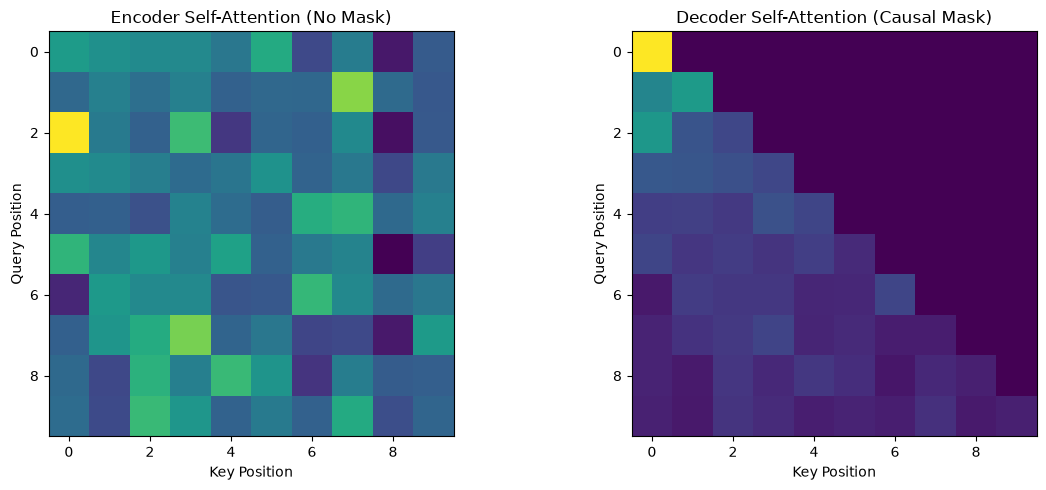

Heatmaps saved to docs/attention_heatmaps.png


In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(weights_1[0].detach().numpy(), cmap='viridis')
ax[0].set_title('Encoder Self-Attention (No Mask)')
ax[0].set_xlabel('Key Position')
ax[0].set_ylabel('Query Position')
ax[0].grid(False)

ax[1].imshow(weights_causal[0].detach().numpy(), cmap='viridis')
ax[1].set_title('Decoder Self-Attention (Causal Mask)')
ax[1].set_xlabel('Key Position')
ax[1].set_ylabel('Query Position')
ax[1].grid(False)

plt.tight_layout()
plt.savefig('../docs/attention_heatmaps.png', dpi=150)
plt.show()
print("Heatmaps saved to docs/attention_heatmaps.png")